# Example 3.1 — Most potent ligands for a target (EGFR)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:18Z
- **Contents:** 1 exchange · 4 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/3.1-ligands-for-target-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 3.1-ligands-for-target-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 3.1-ligands-for-target-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/3.1-ligands-for-target-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 3.1-ligands-for-target-notebook-rerun.ipynb 3.1-ligands-for-target-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

What are the 20 most potent EGFR inhibitors in BindingDB with a Ki or Kd below 1 nM?

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:16 UTC
await replay.call(1, 'search_targets', {'query': 'EGFR', 'organism': 'Homo sapiens'},
                  sha256='5566f990ce0794d4346e8e871914fee0fedd74c2c1d74ee7ccd09953b8554b9e')

**Call 1** · `search_targets` · recorded result · sha256 `5566f990ce07…`

_20 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 520 | Epidermal growth factor receptor | P00533 | P00533 | Homo sapiens | Receptor Kinase Domain | 23267 | 14127 | EGFR |
| polymer | 60 | Epidermal growth factor receptor \[T790M,L858R\] | P00533 | P00533\[T790M,L858R\] | Homo sapiens |  | 1536 | 1276 | EGFR |
| polymer | 1058 | Epidermal growth factor receptor \[L858R,T790M,C797S\] | P00533 | P00533\[L858R,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 703 | 679 | EGFR |
| polymer | 1214 | Epidermal growth factor receptor \[L858R,C797S\] | P00533 | P00533\[L858R,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 684 | 683 | EGFR |
| polymer | 51 | Epidermal growth factor receptor \[L858R\] | P00533 | P00533\[L858R\] | Homo sapiens |  | 678 | 646 | EGFR |
| polymer | 1198 | Epidermal growth factor receptor \[1-18,20-1210,T790M,C797S\] | P00533 | P00533\[1-18,20-1210,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 478 | 451 | EGFR |
| polymer | 1197 | Epidermal growth factor receptor \[1-18,20-1210,C797S\] | P00533 | P00533\[1-18,20-1210,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 428 | 415 | EGFR |
| polymer | 1253 | Epidermal growth factor receptor \[1-770,'NPG',771-1210\] | P00533 | P00533\[1-770,'NPG',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 415 | 410 | EGFR |
| polymer | 1252 | Epidermal growth factor receptor \[1-770,'SVD',771-1210\] | P00533 | P00533\[1-770,'SVD',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 302 | 282 | EGFR |
| polymer | 535 | Epidermal growth factor receptor \[1-745,751-1210\] | P00533 | P00533\[1-745,751-1210\] | Homo sapiens | Enzyme Catalytic Domain | 246 | 245 | EGFR |
| polymer | 243 | Epidermal growth factor receptor \[T790M\] | P00533 | P00533\[T790M\] | Homo sapiens | Enzyme | 229 | 213 | EGFR |
| polymer | 1148 | Epidermal growth factor receptor \[695-1022,T790M,C797S,L858R\] | P00533 | P00533\[695-1022,T790M,C797S,L858R\] | Homo sapiens | Enzyme Catalytic Domain | 151 | 130 | EGFR |
| polymer | 1200 | Epidermal growth factor receptor \[1-18,20-1210\] | P00533 | P00533\[1-18,20-1210\] | Homo sapiens | Enzyme Catalytic Domain | 150 | 150 | EGFR |
| polymer | 1150 | Epidermal growth factor receptor \[695-1022\] | P00533 | P00533\[695-1022\] | Homo sapiens | Enzyme Catalytic Domain | 142 | 124 | EGFR |
| polymer | 1201 | Epidermal growth factor receptor \[1-18,20-1210,T790M\] | P00533 | P00533\[1-18,20-1210,T790M\] | Homo sapiens | Enzyme Catalytic Domain | 95 | 83 | EGFR |
| polymer | 1217 | Epidermal growth factor receptor \[669-770,'SVD',771-1210\] | P00533 | P00533\[669-770,'SVD',771-1210\] | Homo sapiens | Enzyme Catalytic Domain | 73 | 45 | EGFR |
| polymer | 1251 | Epidermal growth factor receptor \[S768I\] | P00533 | P00533\[S768I\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1254 | Epidermal growth factor receptor \[1-769,'SVD',770-1210\] | P00533 | P00533\[1-769,'SVD',770-1210\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1255 | Epidermal growth factor receptor \[1-769,'SV',770-1210\] | P00533 | P00533\[1-769,'SV',770-1210\] | Homo sapiens | Enzyme Catalytic Domain | 58 | 58 | EGFR |
| polymer | 1127 | Epidermal growth factor receptor \[695-745,751-1022,T790M,C797S\] | P00533 | P00533\[695-745,751-1022,T790M,C797S\] | Homo sapiens | Enzyme Catalytic Domain | 49 | 49 | EGFR |


In [ ]:
# Call 2 · find_ligands_for_target · ran 2026-11-24 04:55:16 UTC
await replay.call(2, 'find_ligands_for_target', {'target_id': 520, 'affinity_types': ['Ki', 'Kd'], 'max_value_nm': 1, 'limit': 20},
                  sha256='a9150ec1d4327cd52c0fe2cbb6c535c005a6557559914c76415b1ba2e619e5f9')

**Call 2** · `find_ligands_for_target` · recorded result · sha256 `a9150ec1d432…`

_20 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50029862 | Ki | = | 0.006 | nM | 11.22 | 3032 | PD153035 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_473565 (CHEMBL940057) | 18077363 | 10.1073/pnas.0708800104 | 2007 | 0.7 | 7.07 |  | 1 |
| 50743804 | Ki | = | 0.07 | nM | 10.15 | 50238182 | CHEMBL4100860 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1663485 (CHEMBL4013166) | 28603991 | 10.1021/acs.jmedchem.7b00316 | 2017 | 0.39 | 5.07 |  | 1 |
| 50189274 | Kd | = | 0.1 | nM | 10 | 4779 | Canertinib | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_774487 (CHEMBL1908704) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.4 | 5.61 |  | 31 |
| 50196625 | Kd | = | 0.1 | nM | 10 | 50322823 | AFATINIB | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_774478 (CHEMBL1908695) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.4 | 5.61 |  | 13 |
| 50247882 | Ki | = | 0.1 | nM | 10 | 5446 | Tarceva | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1440951 (CHEMBL3375801) | 25383627 | 10.1021/jm501578n | 2014 | 0.47 | 6.59 |  | 28 |
| 50552347 | Ki | = | 0.14 | nM | 9.85 | 50210162 | CHEMBL3883534 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1634421 (CHEMBL3877213) | 28280261 | 10.1038/nrd.2016.266 | 2017 | 0.52 | 5.55 |  | 1 |
| 51576457 | Kd | \< | 0.2 | nM | 9.7 | 50634310 | CHEMBL5394686 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2380612 | 37934858 | 10.1021/acs.jmedchem.3c01669 | 2023 | 0.42 | 5.97 |  | 1 |
| 65451 | Kd | = | 0.23 | nM | 9.64 | 31090 | Pelitinib | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | Kinase Inhibitor Selectivity Profiling Assay | aid1433 |  | 2008 | 0.4 | 4.54 |  | 19 |
| 51286039 | Kd | = | 0.27 | nM | 9.57 | 50314989 | N-(3-Ethynylphenyl)-6,7-dimethoxyquinolin-4-amine | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1892585 (CHEMBL4394506) | 30973735 | 10.1021/acs.jmedchem.9b00350 | 2019 | 0.57 | 5.59 |  | 1 |
| 51311650 | Kd | = | 0.3 | nM | 9.52 | 50383274 | CHEMBL1229592 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1922306 (CHEMBL4425262) | 26882288 | 10.1021/acs.jmedchem.5b00840 | 2016 | 0.37 | 4.97 |  | 2 |
| 50178943 | Kd | = | 0.35 | nM | 9.46 | 2579 | Staurosporine | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_774484 (CHEMBL1908701) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.37 | 5.11 |  | 2 |
| 50743818 | Ki | = | 0.35 | nM | 9.46 | 50238177 | CHEMBL4098072 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1663485 (CHEMBL4013166) | 28603991 | 10.1021/acs.jmedchem.7b00316 | 2017 | 0.38 | 3.58 |  | 1 |
| 51525437 | Ki | = | 0.35 | nM | 9.46 | 50613695 | CHEMBL5274166 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2293073 | 27564586 | 10.1021/acs.jmedchem.6b00995 | 2016 | 0.39 | 7.01 |  | 1 |
| 50181111 | Kd | = | 0.37 | nM | 9.43 | 50161957 | NERATINIB | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_774478 (CHEMBL1908695) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.32 | 3.5 |  | 8 |
| 50917515 | Ki | = | 0.4 | nM | 9.4 | 5447 | Iressa | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_660429 (CHEMBL1250019) | 15975507 | 10.1016/j.chembiol.2005.04.011 | 2005 | 0.42 | 5.12 |  | 23 |
| 51604168 | Ki | = | 0.4 | nM | 9.4 | 50338602 | Iressa | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2476250 | 38852338 | 10.1016/j.ejmech.2024.116540 |  | 0.42 | 5.12 |  | 1 |
| 51286040 | Kd | = | 0.55 | nM | 9.26 | 50095259 | N-(3-ethynylphenyl)-6,7-dimethoxyquinazolin-4-amine | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1892585 (CHEMBL4394506) | 30973735 | 10.1021/acs.jmedchem.9b00350 | 2019 | 0.55 | 5.89 |  | 1 |
| 50220999 | Kd | = | 0.6 | nM | 9.22 | 50399676 | CHEMBL2178352 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_876721 (CHEMBL2183192) | 23116168 | 10.1021/jm301365e | 2012 | 0.36 | 4.04 | anil\_di\_alk\_A(478) | 1 |
| 50459689 | Ki | = | 0.6 | nM | 9.22 | 50141636 | CHEMBL3758502 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_1551285 (CHEMBL3762136) | 26639762 | 10.1016/j.bmcl.2015.11.078 | 2016 | 0.49 | 5.97 |  | 1 |
| 51525430 | Ki | \< | 0.6 | nM | 9.22 | 50613687 | CHEMBL5285503 | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2293072 | 27564586 | 10.1021/acs.jmedchem.6b00995 | 2016 | 0.35 | 7.04 |  | 1 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:16 UTC
sql = """
    SELECT a.monomerid, c.name AS compound_name, c.inchi_key, c.smiles, count(*) FILTER (WHERE a.affinity_type='Ki') AS n_ki, median(a.value) FILTER (WHERE a.affinity_type='Ki') AS median_ki_nm, min(a.value) FILTER (WHERE a.affinity_type='Ki') AS best_ki_nm, count(*) FILTER (WHERE a.affinity_type='Kd') AS n_kd, median(a.value) FILTER (WHERE a.affinity_type='Kd') AS median_kd_nm, min(a.value) FILTER (WHERE a.affinity_type='Kd') AS best_kd_nm FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 520 AND a.affinity_type IN ('Ki','Kd') AND a.monomerid IN (3032,50238182,4779,50322823,5446,50210162,50634310,31090,50314989,50383274,2579,50238177,50613695,50161957,5447,50338602,50095259,50399676,50141636,50613687) GROUP BY a.monomerid, c.name, c.inchi_key, c.smiles ORDER BY least(coalesce(best_ki_nm,1e9), coalesce(best_kd_nm,1e9)), a.monomerid
    
"""
await replay.call(3, 'run_sql', {'sql': sql, 'limit': 50},
                  sha256='19180a19b956b07af9844a5b43dab2a7a5db05ea061da252990aa3644a5b36b7')

**Call 3** · `run_sql` · recorded result · sha256 `19180a19b956…`

_20 rows_

| monomerid | compound_name | inchi_key | smiles | n_ki | median_ki_nm | best_ki_nm | n_kd | median_kd_nm | best_kd_nm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3032 | PD153035 | LSPANGZZENHZNJ-UHFFFAOYSA-N | COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC | 1 | 0.006 | 0.006 | 0 |  |  |
| 50238182 | CHEMBL4100860 | MMTJMDKKUIMADW-UHFFFAOYSA-N | C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3\[nH\]c(CCCO)nc3-c3ccc(F)cc3)ccn2)c1 | 1 | 0.07 | 0.07 | 0 |  |  |
| 4779 | Canertinib | OMZCMEYTWSXEPZ-UHFFFAOYSA-N | C=CC(=O)Nc1cc2c(cc1OCCCN3CCOCC3)ncnc2Nc4ccc(c(c4)Cl)F | 2 | 8 | 7.1 | 32 | 0.205 | 0.1 |
| 5446 | Tarceva | AAKJLRGGTJKAMG-UHFFFAOYSA-N | COCCOc1cc2c(cc1OCCOC)ncnc2Nc3cccc(c3)C#C | 6 | 1.4 | 0.1 | 35 | 0.67 | 0.35 |
| 50322823 | AFATINIB | ULXXDDBFHOBEHA-CWDCEQMOSA-N | CN(C)C/C=C/C(=O)Nc1cc2c(cc1O\[C@H\]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F | 2 | 22.825 | 0.65 | 13 | 0.19 | 0.1 |
| 50210162 | CHEMBL3883534 | TUYDDIWQXWTNSW-UHFFFAOYSA-N | COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)C=C | 1 | 0.14 | 0.14 | 0 |  |  |
| 50634310 | CHEMBL5394686 | OXIJKGCVPJOUEO-UHFFFAOYSA-N | COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1OCCON1CCN(C)CC1 | 0 |  |  | 1 | 0.2 | 0.2 |
| 31090 | Pelitinib | WVUNYSQLFKLYNI-AATRIKPKSA-N | CCOc1cc2c(cc1NC(=O)/C=C/CN(C)C)c(c(cn2)C#N)Nc3ccc(c(c3)Cl)F | 0 |  |  | 19 | 0.38 | 0.23 |
| 50314989 | N-(3-Ethynylphenyl)-6,7-dimethoxyquinolin-4-amine | WMAOMQUWVSXRPR-UHFFFAOYSA-N | COc1cc2nccc(Nc3cccc(c3)C#C)c2cc1OC | 0 |  |  | 1 | 0.27 | 0.27 |
| 50383274 | CHEMBL1229592 | ITTRLTNMFYIYPA-UHFFFAOYSA-N | CN1CCN(CC1)c2ccc(c(c2)OC)Nc3ncc(c(n3)Oc4cccc(c4)NC(=O)C=C)Cl | 0 |  |  | 11 | 14 | 0.3 |
| 2579 | Staurosporine | HKSZLNNOFSGOKW-FYTWVXJKSA-N | C\[C@@\]12\[C@@H\](\[C@@H\](C\[C@@H\](O1)n3c4ccccc4c5c3c6n2c7ccccc7c6c8c5C(=O)NC8)NC)OC | 0 |  |  | 25 | 270 | 0.35 |
| 50238177 | CHEMBL4098072 | KCECKKYASSKRNU-UHFFFAOYSA-N | C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3\[nH\]c(SC)nc3-c3ccc(F)cc3)ccn2)c1 | 6 | 99 | 0.35 | 0 |  |  |
| 50613695 | CHEMBL5274166 | BDEDFXSJTOMMGU-UHFFFAOYSA-N | CC(C)n1cc(C(N)=O)c2cnc(Nc3ccnc(n3)-c3cnn(c3)S(=O)(=O)C3CC3)cc12 | 5 | 1.2 | 0.35 | 0 |  |  |
| 50161957 | NERATINIB | JWNPDZNEKVCWMY-VQHVLOKHSA-N | CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C | 2 | 5.7 | 4.5 | 13 | 0.93 | 0.37 |
| 5447 | Iressa | XGALLCVXEZPNRQ-UHFFFAOYSA-N | COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F | 8 | 8.7 | 0.4 | 42 | 1 | 0.52 |
| 50338602 | Iressa | XGALLCVXEZPNRQ-UHFFFAOYSA-N | COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F | 1 | 0.4 | 0.4 | 0 |  |  |
| 50095259 | N-(3-ethynylphenyl)-6,7-dimethoxyquinazolin-4-amine | XOTGKYTUNDYTBS-UHFFFAOYSA-N | COc1cc2ncnc(Nc3cccc(c3)C#C)c2cc1OC | 0 |  |  | 1 | 0.55 | 0.55 |
| 50141636 | CHEMBL3758502 | WNGDCEKCMKAXBU-UHFFFAOYSA-N | CC1(C)OCc2c(Nc3n\[nH\]c4ccccc34)nc(-c3cn\[nH\]c3)nc21 | 1 | 0.6 | 0.6 | 0 |  |  |
| 50399676 | CHEMBL2178352 | QPOURHROVVCOHC-UHFFFAOYSA-N | CN1CCN(CC1)c2ccc(cc2)Nc3ncc4c(n3)n(c(n4)Nc5ccccc5)C6CCCC6 | 0 |  |  | 1 | 0.6 | 0.6 |
| 50613687 | CHEMBL5285503 | HNTONTFODLPNDG-UHFFFAOYSA-N | CC(C)n1nc(N2CC(CO)C2)c2cnc(Nc3ccnc(n3)-c3cnn(c3)S(=O)(=O)C3CC3)cc12 | 2 | 1.3 | 0.6 | 0 |  |  |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:17 UTC
sql = """
    SELECT monomerid, affinity_type, relation, value, source_id, ki_result_id FROM activity WHERE polymerid=520 AND affinity_type=$$Ki$$ AND monomerid IN (5446,50322823,4779,50161957,5447,50613687) ORDER BY monomerid, value, ki_result_id
    
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='1a1210b9bbbcd019664cee363d8bdf152e7ea8fee2b4c96277f77abed8f8bd88')

**Call 4** · `run_sql` · recorded result · sha256 `1a1210b9bbbc…`

_22 rows_

| monomerid | affinity_type | relation | value | source_id | ki_result_id |
| --- | --- | --- | --- | --- | --- |
| 4779 | Ki | = | 7.1 | 38134304 | 51593283 |
| 4779 | Ki | = | 8.9 | 38134304 | 51593274 |
| 5446 | Ki | = | 0.1 | 25383627 | 50247882 |
| 5446 | Ki | = | 0.1 | 26639762 | 50459684 |
| 5446 | Ki | = | 0.1 | 26819674 | 50485154 |
| 5446 | Ki | = | 2.7 | 9354447 | 51623177 |
| 5446 | Ki | = | 45 | 28478927 | 50761674 |
| 5446 | Ki | = | 1.37e+07 | 39299082 | 51632313 |
| 5447 | Ki | = | 0.4 | 15975507 | 50917515 |
| 5447 | Ki | = | 2.1 | 12384534 | 51622484 |
| 5447 | Ki | = | 2.5 | 37669428 | 51563627 |
| 5447 | Ki | = | 6.4 | 37669428 | 51563625 |
| 5447 | Ki | = | 11 | 37669428 | 51563628 |
| 5447 | Ki | = | 15 | 12384534 | 51622485 |
| 5447 | Ki | = | 16 | 37669428 | 51563624 |
| 5447 | Ki | = | 26 | 37669428 | 51563626 |
| 50161957 | Ki | = | 4.5 | 38134304 | 51593282 |
| 50161957 | Ki | = | 6.9 | 38134304 | 51593273 |
| 50322823 | Ki | = | 0.65 | 38134304 | 51593272 |
| 50322823 | Ki | = | 45 | 38134304 | 51593281 |
| 50613687 | Ki | \< | 0.6 | 27564586 | 51525430 |
| 50613687 | Ki | = | 2 | 27564586 | 51525470 |


**Figure 1: Most potent EGFR ligands by best Ki or Kd (≤ 1 nM).** _(as recorded)_

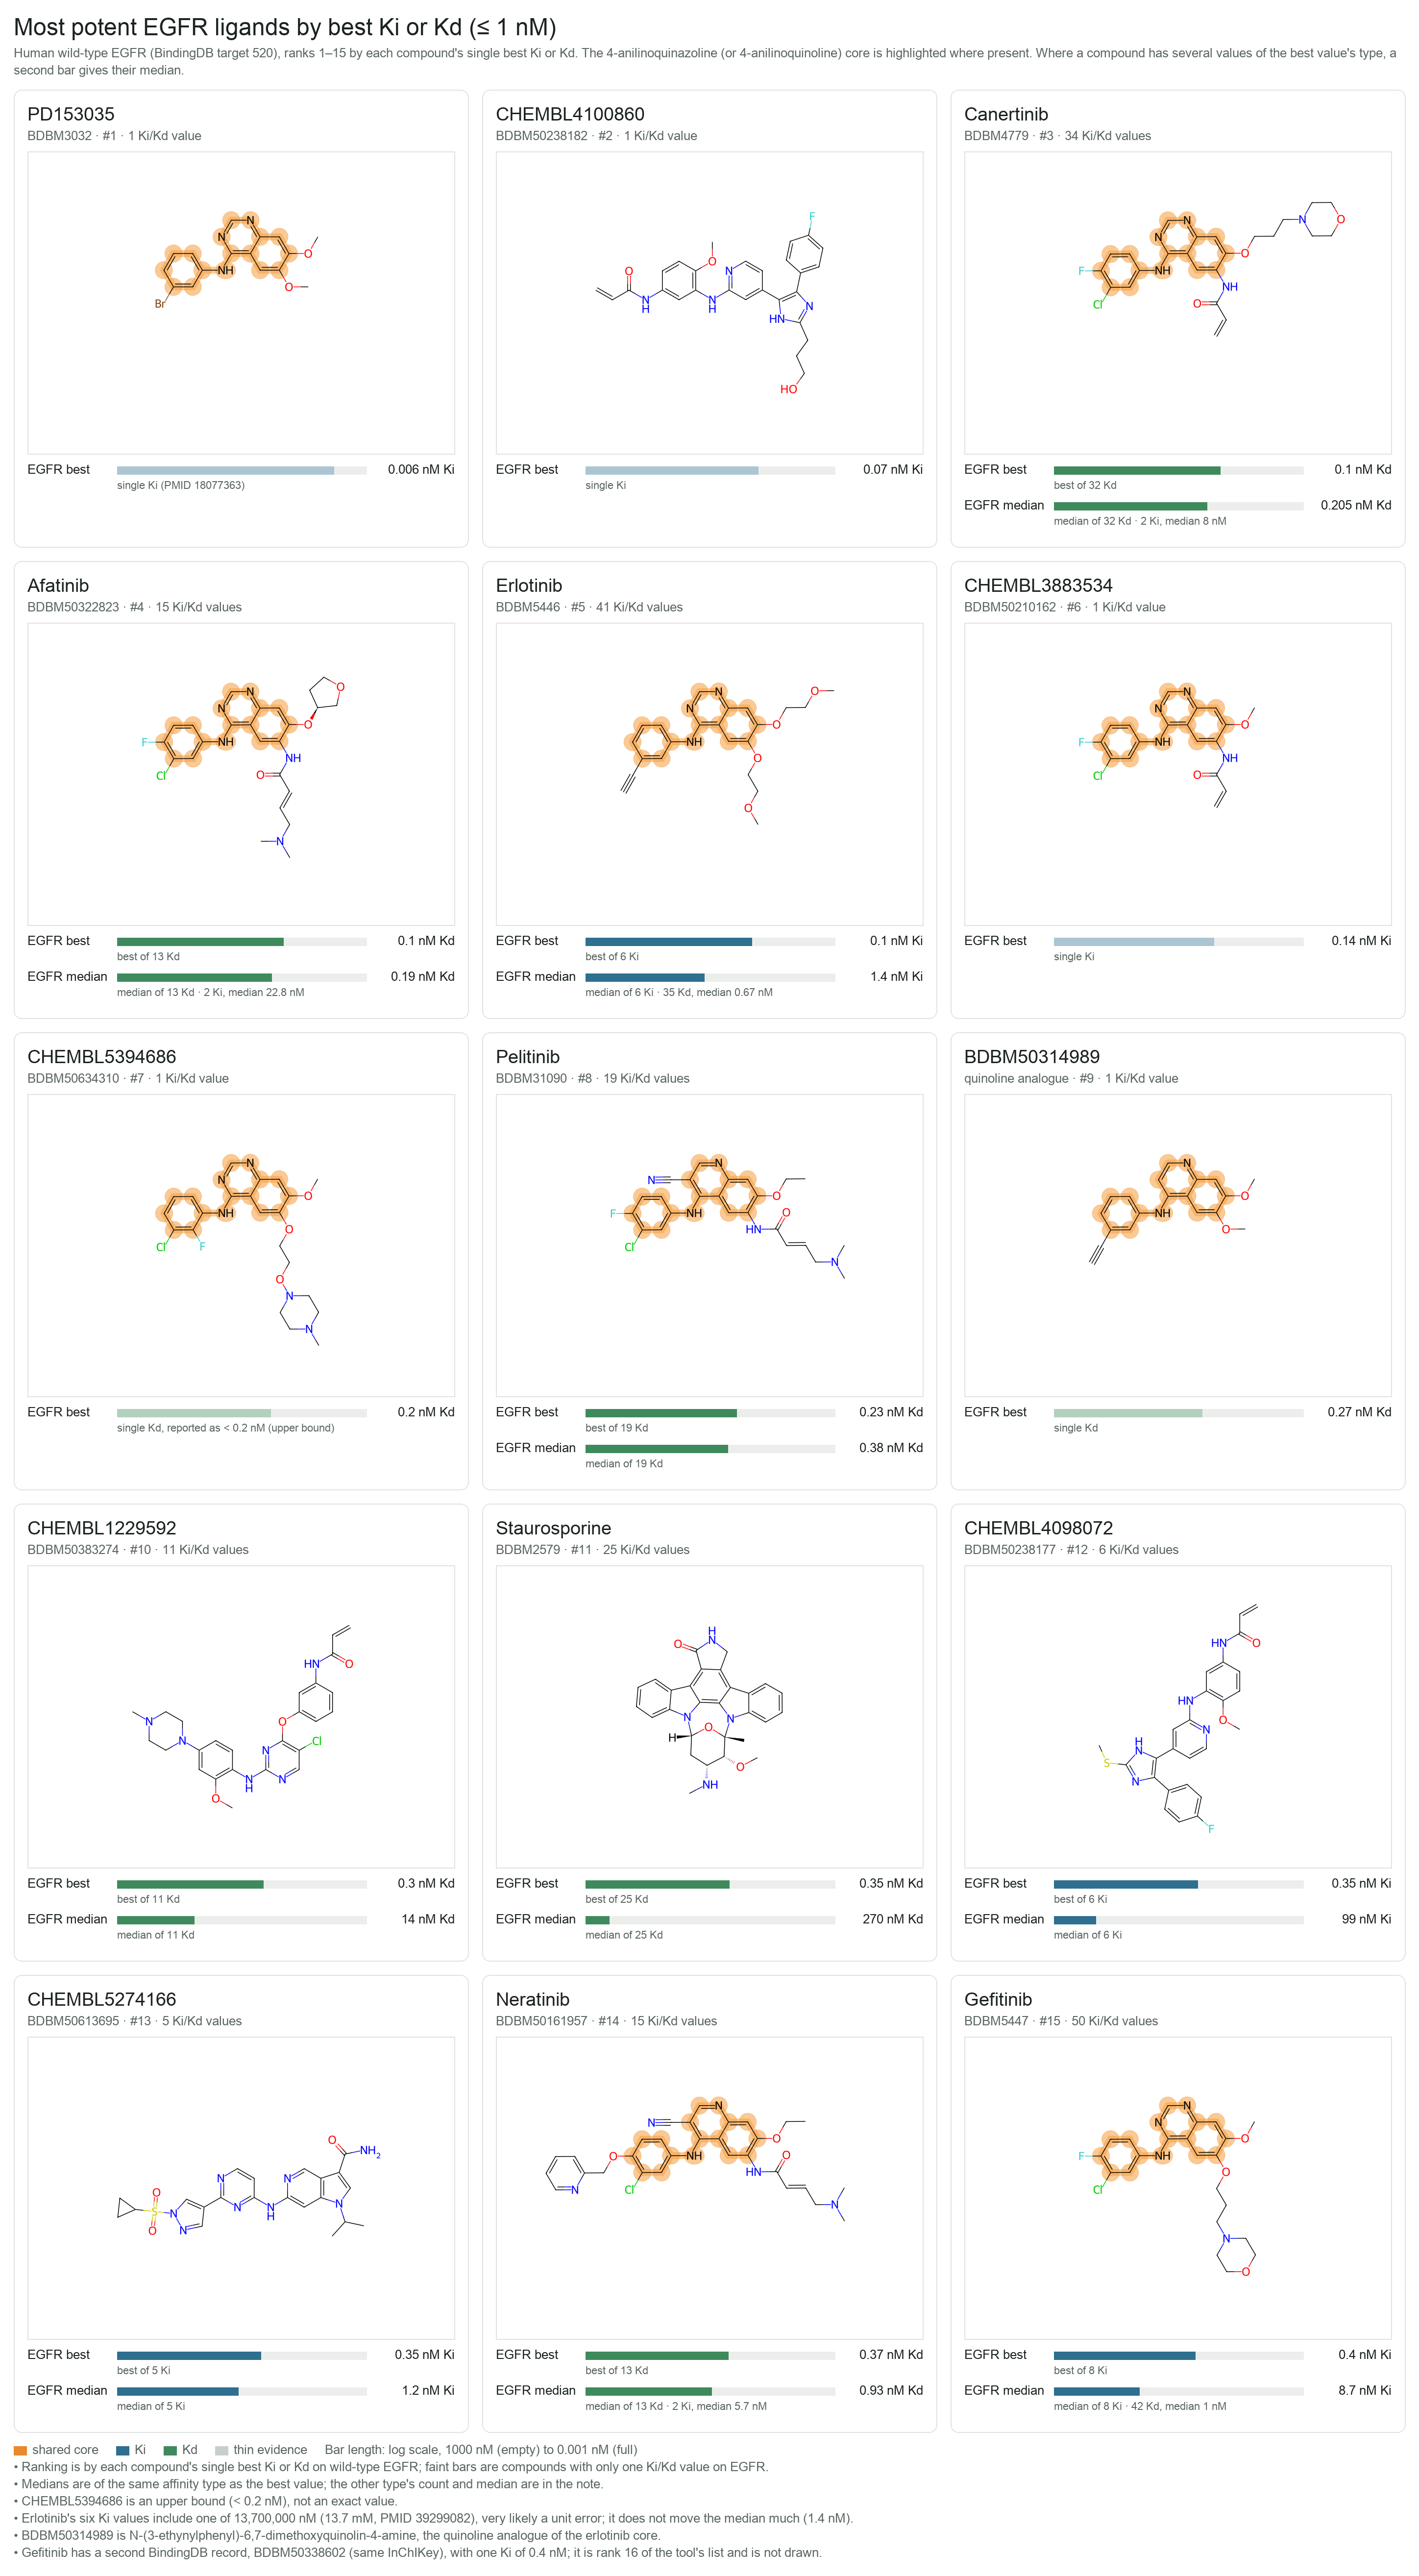

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Most potent EGFR ligands by best Ki or Kd (≤ 1 nM)',
    'compounds': [
        {
            'smiles': 'COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OC',
            'title': 'PD153035',
            'subtitle': 'BDBM3032 · #1 · 1 Ki/Kd value',
            'bars': [
                {
                    'label': 'EGFR best',
                    'value_nm': 0.006,
                    'type': 'Ki',
                    'note': 'single Ki (PMID 18077363)',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3[nH]c(CCCO)nc3-c3ccc(F)cc3)ccn2)c1',
            'title': 'CHEMBL4100860',
            'subtitle': 'BDBM50238182 · #2 · 1 Ki/Kd value',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.07, 'type': 'Ki', 'note': 'single Ki', 'faint': True},
            ],
        },
        {
            'smiles': 'C=CC(=O)Nc1cc2c(cc1OCCCN3CCOCC3)ncnc2Nc4ccc(c(c4)Cl)F',
            'title': 'Canertinib',
            'subtitle': 'BDBM4779 · #3 · 34 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.1, 'type': 'Kd', 'note': 'best of 32 Kd'},
                {
                    'label': 'EGFR median',
                    'value_nm': 0.205,
                    'type': 'Kd',
                    'note': 'median of 32 Kd · 2 Ki, median 8 nM',
                },
            ],
        },
        {
            'smiles': 'CN(C)C/C=C/C(=O)Nc1cc2c(cc1O[C@H]3CCOC3)ncnc2Nc4ccc(c(c4)Cl)F',
            'title': 'Afatinib',
            'subtitle': 'BDBM50322823 · #4 · 15 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.1, 'type': 'Kd', 'note': 'best of 13 Kd'},
                {
                    'label': 'EGFR median',
                    'value_nm': 0.19,
                    'type': 'Kd',
                    'note': 'median of 13 Kd · 2 Ki, median 22.8 nM',
                },
            ],
        },
        {
            'smiles': 'COCCOc1cc2c(cc1OCCOC)ncnc2Nc3cccc(c3)C#C',
            'title': 'Erlotinib',
            'subtitle': 'BDBM5446 · #5 · 41 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.1, 'type': 'Ki', 'note': 'best of 6 Ki'},
                {
                    'label': 'EGFR median',
                    'value_nm': 1.4,
                    'type': 'Ki',
                    'note': 'median of 6 Ki · 35 Kd, median 0.67 nM',
                },
            ],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)C=C',
            'title': 'CHEMBL3883534',
            'subtitle': 'BDBM50210162 · #6 · 1 Ki/Kd value',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.14, 'type': 'Ki', 'note': 'single Ki', 'faint': True},
            ],
        },
        {
            'smiles': 'COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1OCCON1CCN(C)CC1',
            'title': 'CHEMBL5394686',
            'subtitle': 'BDBM50634310 · #7 · 1 Ki/Kd value',
            'bars': [
                {
                    'label': 'EGFR best',
                    'value_nm': 0.2,
                    'type': 'Kd',
                    'note': 'single Kd, reported as < 0.2 nM (upper bound)',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CCOc1cc2c(cc1NC(=O)/C=C/CN(C)C)c(c(cn2)C#N)Nc3ccc(c(c3)Cl)F',
            'title': 'Pelitinib',
            'subtitle': 'BDBM31090 · #8 · 19 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.23, 'type': 'Kd', 'note': 'best of 19 Kd'},
                {'label': 'EGFR median', 'value_nm': 0.38, 'type': 'Kd', 'note': 'median of 19 Kd'},
            ],
        },
        {
            'smiles': 'COc1cc2nccc(Nc3cccc(c3)C#C)c2cc1OC',
            'title': 'BDBM50314989',
            'subtitle': 'quinoline analogue · #9 · 1 Ki/Kd value',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.27, 'type': 'Kd', 'note': 'single Kd', 'faint': True},
            ],
        },
        {
            'smiles': 'CN1CCN(CC1)c2ccc(c(c2)OC)Nc3ncc(c(n3)Oc4cccc(c4)NC(=O)C=C)Cl',
            'title': 'CHEMBL1229592',
            'subtitle': 'BDBM50383274 · #10 · 11 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.3, 'type': 'Kd', 'note': 'best of 11 Kd'},
                {'label': 'EGFR median', 'value_nm': 14.0, 'type': 'Kd', 'note': 'median of 11 Kd'},
            ],
        },
        {
            'smiles': 'C[C@@]12[C@@H]([C@@H](C[C@@H](O1)n3c4ccccc4c5c3c6n2c7ccccc7c6c8c5C(=O)NC8)NC)OC',
            'title': 'Staurosporine',
            'subtitle': 'BDBM2579 · #11 · 25 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.35, 'type': 'Kd', 'note': 'best of 25 Kd'},
                {'label': 'EGFR median', 'value_nm': 270.0, 'type': 'Kd', 'note': 'median of 25 Kd'},
            ],
        },
        {
            'smiles': 'C=CC(=O)Nc1ccc(OC)c(Nc2cc(-c3[nH]c(SC)nc3-c3ccc(F)cc3)ccn2)c1',
            'title': 'CHEMBL4098072',
            'subtitle': 'BDBM50238177 · #12 · 6 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.35, 'type': 'Ki', 'note': 'best of 6 Ki'},
                {'label': 'EGFR median', 'value_nm': 99.0, 'type': 'Ki', 'note': 'median of 6 Ki'},
            ],
        },
        {
            'smiles': 'CC(C)n1cc(C(N)=O)c2cnc(Nc3ccnc(n3)-c3cnn(c3)S(=O)(=O)C3CC3)cc12',
            'title': 'CHEMBL5274166',
            'subtitle': 'BDBM50613695 · #13 · 5 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.35, 'type': 'Ki', 'note': 'best of 5 Ki'},
                {'label': 'EGFR median', 'value_nm': 1.2, 'type': 'Ki', 'note': 'median of 5 Ki'},
            ],
        },
        {
            'smiles': 'CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2cc1NC(=O)\\C=C\\CN(C)C',
            'title': 'Neratinib',
            'subtitle': 'BDBM50161957 · #14 · 15 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.37, 'type': 'Kd', 'note': 'best of 13 Kd'},
                {
                    'label': 'EGFR median',
                    'value_nm': 0.93,
                    'type': 'Kd',
                    'note': 'median of 13 Kd · 2 Ki, median 5.7 nM',
                },
            ],
        },
        {
            'smiles': 'COc1cc2c(cc1OCCCN3CCOCC3)c(ncn2)Nc4ccc(c(c4)Cl)F',
            'title': 'Gefitinib',
            'subtitle': 'BDBM5447 · #15 · 50 Ki/Kd values',
            'bars': [
                {'label': 'EGFR best', 'value_nm': 0.4, 'type': 'Ki', 'note': 'best of 8 Ki'},
                {
                    'label': 'EGFR median',
                    'value_nm': 8.7,
                    'type': 'Ki',
                    'note': 'median of 8 Ki · 42 Kd, median 1 nM',
                },
            ],
        },
    ],
    'align_to': 'c1ccccc1Nc1[c,n]cnc2ccccc12',
    'columns': 3,
    'description': "Human wild-type EGFR (BindingDB target 520), ranks 1–15 by each compound's single best Ki or Kd. The 4-anilinoquinazoline (or 4-anilinoquinoline) core is highlighted where present. Where a compound has several values of the best value's type, a second bar gives their median.",
    'notes': [
        "Ranking is by each compound's single best Ki or Kd on wild-type EGFR; faint bars are compounds with only one Ki/Kd value on EGFR.",
        "Medians are of the same affinity type as the best value; the other type's count and median are in the note.",
        'CHEMBL5394686 is an upper bound (< 0.2 nM), not an exact value.',
        "Erlotinib's six Ki values include one of 13,700,000 nM (13.7 mM, PMID 39299082), very likely a unit error; it does not move the median much (1.4 nM).",
        'BDBM50314989 is N-(3-ethynylphenyl)-6,7-dimethoxyquinolin-4-amine, the quinoline analogue of the erlotinib core.',
        "Gefitinib has a second BindingDB record, BDBM50338602 (same InChIKey), with one Ki of 0.4 nM; it is rank 16 of the tool's list and is not drawn.",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

BindingDB has 14,127 compounds measured against human EGFR (wild type, UniProt P00533; BindingDB target id 520). Restricting to Ki or Kd ≤ 1 nM still leaves more than 20 compounds. The grid below shows the 15 most potent, ranked by each compound's single best Ki or Kd, with its structure and a bar for that value. Where a compound has several values of the same type, a second bar gives their median; faint bars are compounds with a single Ki/Kd value on EGFR.

The top of the list: PD153035 (Ki 0.006 nM), CHEMBL4100860 (Ki 0.07 nM), then canertinib and afatinib (both Kd 0.1 nM) and erlotinib (Ki 0.1 nM). Pelitinib, neratinib and gefitinib follow at 0.23–0.4 nM. Three compounds tie at 0.35 nM: staurosporine, CHEMBL4098072 and CHEMBL5274166.

Ranks 16–20 are a second BindingDB record for gefitinib (BDBM50338602, same InChIKey as BDBM5447) with one Ki of 0.4 nM, and four single-measurement compounds from medicinal-chemistry papers: the quinazoline erlotinib core without its side chains (BDBM50095259, Kd 0.55 nM), CHEMBL2178352 (Kd 0.6 nM, with a PAINS alert, anil_di_alk_A), CHEMBL3758502 (Ki 0.6 nM) and CHEMBL5285503 (Ki < 0.6 nM, an upper bound). The same drug can sit under two BDBM ids, so a top-N list can count it twice.

Most of the list is the 4-anilinoquinazoline chemotype, highlighted in the grid: PD153035, gefitinib, erlotinib, canertinib, afatinib and two single-paper analogues (CHEMBL3883534 and CHEMBL5394686). Pelitinib and neratinib carry the closely related 3-cyanoquinoline, and one compound (BDBM50314989) is the quinoline version of the erlotinib core. The other five (CHEMBL4100860, CHEMBL1229592, staurosporine, CHEMBL4098072, CHEMBL5274166) lack the core and are drawn unaligned. Eight compounds also carry an acrylamide or crotonamide, the warhead of covalent EGFR inhibitors: canertinib, afatinib, pelitinib, neratinib, the quinazoline CHEMBL3883534, the anilinopyrimidine CHEMBL1229592 and the two anilinopyridines CHEMBL4100860 and CHEMBL4098072.

The grid shows the median of the same affinity type as the best value. Where a compound also has values of the other type, they are summarized here:

| Compound | Ki/Kd values | Other type | Its median |
|---|---|---|---|
| Erlotinib | 41 | 35 Kd | 0.67 nM |
| Gefitinib (BDBM5447) | 50 | 42 Kd | 1.0 nM |
| Canertinib | 34 | 2 Ki | 8.0 nM |
| Afatinib | 15 | 2 Ki | 22.8 nM (0.65 and 45 nM) |
| Neratinib | 15 | 2 Ki | 5.7 nM |

**A data problem:** one of erlotinib's six Ki values on EGFR is 13,700,000 nM (13.7 mM, PMID 39299082), seven orders of magnitude off the others and very likely a unit error in the source or its curation. Erlotinib's Ki median is 1.4 nM with it; the value is an outlier to set aside, not evidence that erlotinib is weak.

**Lesson:** a top-N list ranks single best values. The tool ranks each compound by its one most potent measurement, so a compound measured once in one paper can top a drug measured 40 times. PD153035 is first because of a single Ki of 6 pM. The tool also returns relations: CHEMBL5394686 is listed as "< 0.2 nM", which is an upper bound, not an exact value. Several compounds show how much a single value can overstate potency; the gap between their two bars is the point. Staurosporine has a best Kd of 0.35 nM, but its median over 25 Kd values is 270 nM (pAffinity 6.6). CHEMBL4098072 has a best Ki of 0.35 nM and a median of 99 nM over 6 Ki values. CHEMBL1229592 has a best of 0.3 nM and a median of 14 nM (pAffinity 7.85). Erlotinib's best Ki (0.1 nM) is 14-fold below its Ki median (1.4 nM). Read the number of measurements and the median before you believe a ranking.

### How this was answered

- **search_targets** with query "EGFR", organism "Homo sapiens": found wild-type EGFR (target id 520, 14,127 compounds). It also listed mutant and truncated EGFR constructs as separate targets (see Example 3.3).
- **find_ligands_for_target** with target_id 520, affinity_types [Ki, Kd], max_value_nm 1, limit 20: the most potent compounds, one row per compound.
- **run_sql** on the activity and compound tables: added SMILES, the number of Ki and Kd measurements, and the median of each type for each compound, and checked that the two gefitinib records share an InChIKey. A second query listed the individual Ki values of the drugs with both types, which showed erlotinib's 13.7 mM outlier.
- **draw_structure_grid**: the top 15 compounds with their best and median values as bars, aligned on the 4-anilinoquinazoline/quinoline core (given as `c1ccccc1Nc1[c,n]cnc2ccccc12`, 17 atoms). Left to find the core itself, the tool chose the 8-atom methoxybenzene the compounds share, which is not the chemotype, so the grid was drawn again on the anilinoquinazoline core.

### Try next

- "Compare inhibitors of EGFR wild type with the T790M mutant." (Example 3.3)
- "How many compounds contain a quinazoline core? Show the most potent." (Example 2.3)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 4 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 3.1 — Most potent ligands for a target (EGFR), 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```